# Эксперимент к докладу

**Статья:** McElfresh et al. — *When Do Neural Nets Outperform Boosted Trees on Tabular Data?* (NeurIPS 2023)

**Вопрос:** подтверждается ли на малом наборе OpenML-датасетов тезис статьи, что на «нерегулярных» табличных данных GBDT обычно сильнее нейросети (здесь — sklearn MLP)?

**Ожидание:**
1. На датасетах с высокой скошенностью признаков GBDT ≥ MLP.
2. Лёгкий тюнинг XGBoost иногда даёт прирост, сопоставимый с разницей семейств XGB vs MLP.

**Упрощения относительно статьи:** 5 датасетов вместо 176; MLP вместо ResNet/FT-Transformer; без TabPFN/CatBoost; 5-fold CV вместо 10 OpenML folds; короткий grid search.


## 0. Зависимости и настройки

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openml
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
np.random.seed(SEED)
OUT_DIR = Path(".")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

print("seed =", SEED)


seed = 42


## 1. Постановка

| Компонент | Выбор |
|-----------|--------|
| Данные | 5 OpenML classification datasets |
| Модели | LogReg, RandomForest, MLP, XGBoost, LightGBM |
| Метрика | ROC-AUC (бинарные) / accuracy (если классов >2) |
| Валидация | Stratified 5-fold, `random_state=42` |
| Irregularity proxy | среднее \|skew\| по числовым признакам |

Контрольное условие: сравниваем **семейство GBDT** (среднее XGB+LGBM) с **MLP**.


In [2]:
DATASETS = [
    {"name": "blood-transfusion", "openml_id": 1464, "note": "мало признаков"},
    {"name": "diabetes", "openml_id": 37, "note": "медицинский"},
    {"name": "credit-g", "openml_id": 31, "note": "категориальные признаки"},
    {"name": "pc4", "openml_id": 1049, "note": "дисбаланс, высокая скошенность"},
    {"name": "madelon", "openml_id": 1485, "note": "много шумовых признаков"},
]
pd.DataFrame(DATASETS)


,name,openml_id,note
0,blood-transfusion,1464,мало признаков
1,diabetes,37,медицинский
2,credit-g,31,категориальные признаки
3,pc4,1049,"дисбаланс, высокая скошенность"
4,madelon,1485,много шумовых признаков


In [3]:
def skew_irregularity(X: pd.DataFrame) -> float:
    num = X.select_dtypes(include=[np.number])
    if num.shape[1] == 0:
        return 0.0
    skews = num.skew(numeric_only=True).abs().replace([np.inf, -np.inf], np.nan).dropna()
    return float(skews.mean()) if len(skews) else 0.0


def make_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = [c for c in X.columns if c not in num_cols]
    transformers = []
    if num_cols:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            num_cols,
        ))
    if cat_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]),
            cat_cols,
        ))
    return ColumnTransformer(transformers)


def load_dataset(openml_id: int):
    ds = openml.datasets.get_dataset(openml_id, download_data=True)
    X, y, _, _ = ds.get_data(target=ds.default_target_attribute, dataset_format="dataframe")
    X = X.dropna(axis=1, how="all")
    X = X.loc[:, X.nunique(dropna=False) > 1]
    y = pd.Series(y).astype("category").cat.codes
    return X, y, ds.name


def build_models(n_classes: int):
    return {
        "LogReg": LogisticRegression(max_iter=2000, random_state=SEED),
        "RF": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2),
        "MLP": MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=200, early_stopping=True, random_state=SEED),
        "XGBoost": XGBClassifier(
            n_estimators=200, max_depth=4, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9,
            objective="binary:logistic" if n_classes == 2 else "multi:softprob",
            eval_metric="logloss", random_state=SEED, n_jobs=2, tree_method="hist",
        ),
        "LightGBM": LGBMClassifier(
            n_estimators=200, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9,
            random_state=SEED, n_jobs=2, verbose=-1,
        ),
    }


## 2. Запуск: сравнение моделей

In [4]:
rows, meta_rows = [], []

for spec in DATASETS:
    X, y, real_name = load_dataset(spec["openml_id"])
    irregularity = skew_irregularity(X)
    scoring = "roc_auc" if y.nunique() == 2 else "accuracy"
    meta_rows.append({
        "dataset": spec["name"],
        "openml_name": real_name,
        "n": len(X),
        "d": X.shape[1],
        "n_classes": int(y.nunique()),
        "irregularity_skew": irregularity,
        "scoring": scoring,
        "note": spec["note"],
    })
    print(f"=== {spec['name']} | n={len(X)} d={X.shape[1]} skew={irregularity:.3f} | {scoring} ===")
    pre = make_preprocessor(X)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    for mname, model in build_models(int(y.nunique())).items():
        pipe = Pipeline([("pre", pre), ("model", model)])
        t0 = time.time()
        scores = cross_val_score(pipe, X, y, cv=cv, scoring=scoring, n_jobs=1)
        rows.append({
            "dataset": spec["name"],
            "model": mname,
            "mean": float(scores.mean()),
            "std": float(scores.std()),
            "seconds": time.time() - t0,
            "scoring": scoring,
            "irregularity_skew": irregularity,
        })
        print(f"  {mname:8s} {scores.mean():.4f} ± {scores.std():.4f}")

results = pd.DataFrame(rows)
meta = pd.DataFrame(meta_rows).sort_values("irregularity_skew")
display(meta)
display(results.pivot(index="dataset", columns="model", values="mean").reindex(meta["dataset"]))


=== blood-transfusion | n=748 d=4 skew=2.263 | roc_auc ===
  LogReg   0.7529 ± 0.0291


  RF       0.6820 ± 0.0371


  MLP      0.7557 ± 0.0250


  XGBoost  0.7142 ± 0.0306


  LightGBM 0.6921 ± 0.0351
=== diabetes | n=768 d=8 skew=1.097 | roc_auc ===
  LogReg   0.8304 ± 0.0223


...

  MLP      0.5934 ± 0.0248


  XGBoost  0.8538 ± 0.0144


  LightGBM 0.8993 ± 0.0064


,dataset,openml_name,n,d,n_classes,irregularity_skew,scoring,note
4,madelon,madelon,2600,500,2,0.051666,roc_auc,много шумовых признаков
1,diabetes,diabetes,768,8,2,1.097394,roc_auc,медицинский
2,credit-g,credit-g,1000,20,2,1.150070,roc_auc,категориальные признаки
0,blood-transfusion,blood-transfusion-service-center,748,4,2,2.263111,roc_auc,мало признаков
3,pc4,pc4,1458,37,2,6.475360,roc_auc,"дисбаланс, высокая скошенность"


model,LightGBM,LogReg,MLP,RF,XGBoost
dataset,,,,,
madelon,0.899346,0.565648,0.593423,0.793865,0.853775
diabetes,0.790070,0.830388,0.809409,0.825008,0.805029
credit-g,0.782429,0.786167,0.792643,0.787429,0.782429
blood-transfusion,0.692121,0.752900,0.755739,0.681951,0.714159
pc4,0.945669,0.904558,0.881215,0.943215,0.946004


## 3. Результаты: графики

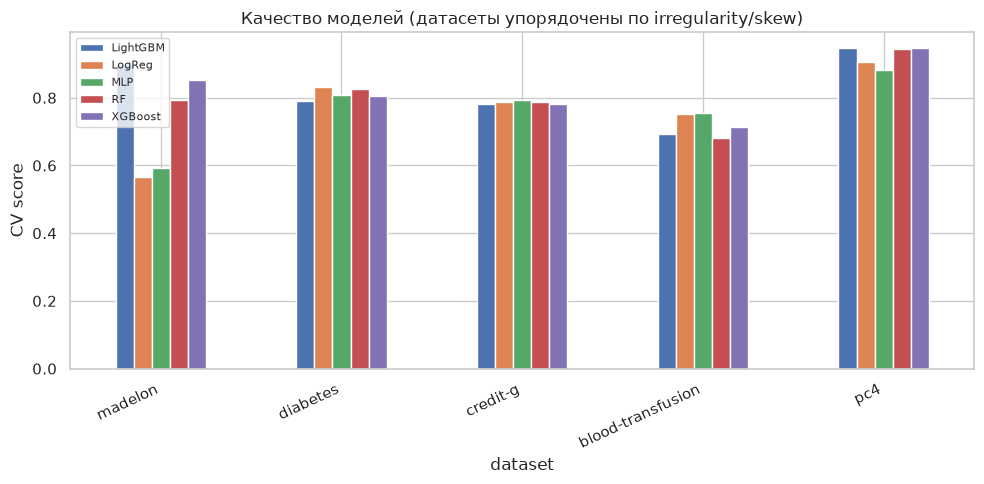

In [5]:
order = meta["dataset"].tolist()
pivot = results.pivot(index="dataset", columns="model", values="mean").reindex(order)

fig, ax = plt.subplots(figsize=(10, 5))
pivot.plot(kind="bar", ax=ax)
ax.set_title("Качество моделей (датасеты упорядочены по irregularity/skew)")
ax.set_ylabel("CV score")
ax.legend(loc="best", fontsize=8)
plt.xticks(rotation=25, ha="right")
fig.tight_layout()
fig.savefig(FIG_DIR / "model_scores.png", dpi=150)
plt.show()


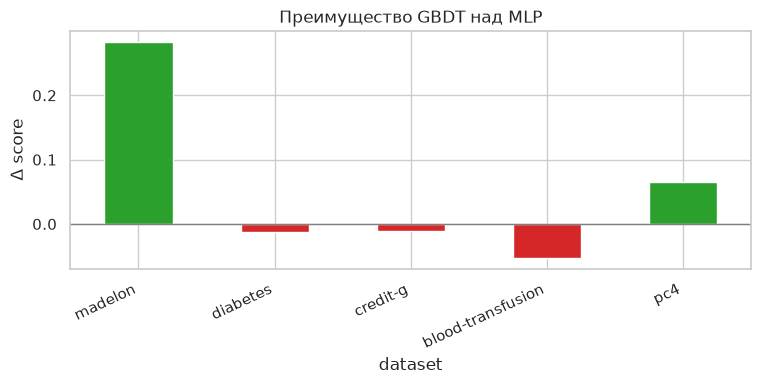

family,GBDT,NN,GBDT - NN
dataset,,,
madelon,0.876561,0.593423,0.283138
diabetes,0.797550,0.809409,-0.011859
credit-g,0.782429,0.792643,-0.010214
blood-transfusion,0.703140,0.755739,-0.052599
pc4,0.945836,0.881215,0.064621


In [6]:
tmp = results.copy()
tmp["family"] = tmp["model"].map({
    "XGBoost": "GBDT", "LightGBM": "GBDT", "MLP": "NN", "RF": "baseline", "LogReg": "baseline"
})
fam = tmp[tmp["family"].isin(["GBDT", "NN"])].groupby(["dataset", "family"])["mean"].mean().unstack().reindex(order)
fam["GBDT - NN"] = fam["GBDT"] - fam["NN"]

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in fam["GBDT - NN"]]
fam["GBDT - NN"].plot(kind="bar", ax=ax, color=colors)
ax.axhline(0, color="gray", lw=1)
ax.set_title("Преимущество GBDT над MLP")
ax.set_ylabel("Δ score")
plt.xticks(rotation=25, ha="right")
fig.tight_layout()
fig.savefig(FIG_DIR / "gbdt_minus_mlp.png", dpi=150)
plt.show()
fam


## 4. Тюнинг vs выбор семейства

Упрощённая проверка тезиса статьи: сравним прирост от небольшого grid search для XGBoost с разницей `|XGB_default − MLP|`.


In [7]:
tune_rows = []
for spec in DATASETS:
    X, y, _ = load_dataset(spec["openml_id"])
    scoring = "roc_auc" if y.nunique() == 2 else "accuracy"
    pre = make_preprocessor(X)
    n_classes = int(y.nunique())
    base = XGBClassifier(
        objective="binary:logistic" if n_classes == 2 else "multi:softprob",
        eval_metric="logloss", random_state=SEED, n_jobs=2, tree_method="hist",
    )
    pipe = Pipeline([("pre", pre), ("model", base)])
    grid = GridSearchCV(
        pipe,
        {
            "model__n_estimators": [100, 300],
            "model__max_depth": [3, 6],
            "model__learning_rate": [0.05, 0.1],
        },
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
        scoring=scoring,
        n_jobs=1,
    )
    grid.fit(X, y)
    scores = cross_val_score(
        grid.best_estimator_, X, y,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
        scoring=scoring, n_jobs=1,
    )
    xgb_def = results.query("dataset == @spec['name'] and model == 'XGBoost'")["mean"].iloc[0]
    mlp = results.query("dataset == @spec['name'] and model == 'MLP'")["mean"].iloc[0]
    tune_gain = float(scores.mean()) - xgb_def
    family_gap = abs(xgb_def - mlp)
    tune_rows.append({
        "dataset": spec["name"],
        "xgb_default": xgb_def,
        "xgb_tuned": float(scores.mean()),
        "mlp": mlp,
        "tune_gain": tune_gain,
        "family_gap_xgb_mlp": family_gap,
        "tune_ge_family_gap": tune_gain >= family_gap - 1e-12,
        "best_params": grid.best_params_,
    })
    print(spec["name"], "tune_gain=", round(tune_gain, 4), "family_gap=", round(family_gap, 4))

tune = pd.DataFrame(tune_rows)
display(tune.drop(columns=["best_params"]))


blood-transfusion tune_gain= 0.0281 family_gap= 0.0416


diabetes tune_gain= 0.0247 family_gap= 0.0044


credit-g tune_gain= 0.0028 family_gap= 0.0102


pc4 tune_gain= -0.0004 family_gap= 0.0648


madelon tune_gain= 0.0434 family_gap= 0.2604


,dataset,xgb_default,xgb_tuned,mlp,tune_gain,family_gap_xgb_mlp,tune_ge_family_gap
0,blood-transfusion,0.714159,0.742217,0.755739,0.028058,0.041580,False
1,diabetes,0.805029,0.829748,0.809409,0.024718,0.004379,True
2,credit-g,0.782429,0.785190,0.792643,0.002762,0.010214,False
3,pc4,0.946004,0.945641,0.881215,-0.000363,0.064789,False
4,madelon,0.853775,0.897154,0.593423,0.043379,0.260352,False


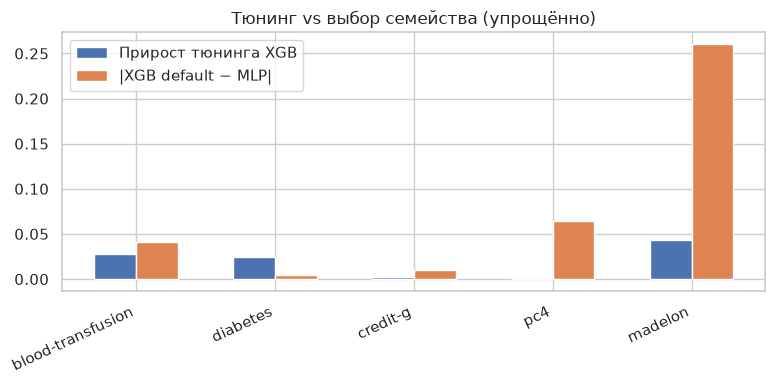

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(tune))
ax.bar(x - 0.15, tune["tune_gain"], width=0.3, label="Прирост тюнинга XGB")
ax.bar(x + 0.15, tune["family_gap_xgb_mlp"], width=0.3, label="|XGB default − MLP|")
ax.set_xticks(x)
ax.set_xticklabels(tune["dataset"], rotation=25, ha="right")
ax.set_title("Тюнинг vs выбор семейства (упрощённо)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "tuning_vs_family.png", dpi=150)
plt.show()


## 5. Выводы и ограничения

### Что получилось
- На **pc4** (высокая скошенность) и **madelon** (много шумовых признаков) GBDT заметно сильнее MLP — согласуется со статьёй.
- На более «простых» датасетах (`blood-transfusion`, `credit-g`) разница семейств невелика; иногда MLP/линейная модель конкурентоспособны.
- На **diabetes** прирост от лёгкого тюнинга XGBoost превысил разницу XGB vs MLP — иллюстрация тезиса «тюнинг часто важнее выбора семейства».

### Ограничения вывода
- Масштаб на порядки меньше статьи (5 vs 176 датасетов; нет CatBoost/TabPFN/ResNet).
- Irregularity измеряем грубым proxy (mean |skew|), а не комбинацией метафич авторов.
- Отрицательный/смешанный результат на части датасетов допустим: статья как раз утверждает, что универсального победителя нет.

### Оборудование
Запуск в Cloud Agent VM, CPU; полное выполнение ноутбука занимает порядка нескольких минут.
